<a href="https://colab.research.google.com/github/ihsann2410010447/projek-statistika-Akbar-Ihsan-Nugraha/blob/main/Milestone2_Uji_Hipotesis_2410010447_Akbar_Ihsan_Nugraha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Milestone 2 — Uji Hipotesis (Statistika Inferensial)

**Mata Kuliah:** Statistika & Probabilitas (TIF1501) · CPMK072 (Sub-CPMK 072.2)
**Nama / NIM:** _isi di sini_
**Dataset:** _nama dataset Milestone 1 Anda_

> **Cara pakai:** (1) isi sel **Konfigurasi** (path dataset & nama kolom), (2) tulis *Insight EDA*, H₀, H₁ dan *Kesimpulan bisnis* di sel markdown tiap hipotesis, (3) jalankan semua sel.
> Secara default notebook memakai **data demo sintetis** agar bisa langsung dijalankan — ganti `DATA_PATH` untuk memakai dataset Anda.

# 🔧 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4.5)
np.random.seed(42)

# 🧰 2. Fungsi Bantu

Fungsi mengikuti pola Bagian C–G notebook M10: cek asumsi → uji → effect size → keputusan. Setiap hasil otomatis masuk ke tabel ringkasan.

In [2]:
ALPHA = 0.05
RESULTS = []  # untuk tabel ringkasan akhir


def _keputusan(p):
    return "TOLAK H0" if p < ALPHA else "GAGAL TOLAK H0"


def _simpan(nama, uji, p, effect_name, effect_val):
    RESULTS.append([nama, uji, p, f"{effect_name} = {effect_val:.3f}", _keputusan(p)])


# ---------- 1. CI 95% ----------
def ci_mean(df, col, conf=0.95):
    x = df[col].dropna()
    n = len(x)
    lo, hi = stats.t.interval(conf, df=n - 1, loc=x.mean(), scale=x.std(ddof=1) / np.sqrt(n))
    print(f"=== CI {conf*100:.0f}% rata-rata '{col}' ===")
    print(f"  n = {n}, mean = {x.mean():.3f}, std = {x.std(ddof=1):.3f}")
    print(f"  CI = [{lo:.3f}, {hi:.3f}]")
    return lo, hi


# ---------- 2. Numerik vs 2 grup ----------
def uji_dua_grup(df, num, grp, nama="", g1=None, g2=None):
    levels = df[grp].dropna().unique()
    g1, g2 = (g1, g2) if g1 is not None else (levels[0], levels[1])
    a = df.loc[df[grp] == g1, num].dropna()
    b = df.loc[df[grp] == g2, num].dropna()

    print(f"=== {num} per {grp}: {g1} vs {g2} ===")
    normal = True
    for lbl, g in [(g1, a), (g2, b)]:
        w, p = stats.shapiro(g if len(g) <= 5000 else g.sample(5000, random_state=42))
        print(f"  Shapiro {lbl}: p={p:.4f} → {'normal' if p > ALPHA else 'TIDAK normal'} (n={len(g)})")
        normal &= p > ALPHA
    lev_p = stats.levene(a, b).pvalue
    print(f"  Levene: p={lev_p:.4f} → varians {'sama' if lev_p > ALPHA else 'BERBEDA'}")

    # n besar (>30/grup) → CLT, t-test tetap robust; selain itu pakai Mann-Whitney bila tidak normal
    if normal or (len(a) > 30 and len(b) > 30):
        stat, p = stats.ttest_ind(a, b, equal_var=(lev_p > ALPHA))
        uji = "Student t" if lev_p > ALPHA else "Welch t"
    else:
        stat, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        uji = "Mann-Whitney U"
    sd = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    d = (a.mean() - b.mean()) / sd
    print(f"  Mean {g1}={a.mean():.3f}, Mean {g2}={b.mean():.3f}, selisih={a.mean()-b.mean():.3f}")
    print(f"  {uji}: stat={stat:.3f}, p={p:.4g}")
    print(f"  Cohen's d = {d:.3f} (0.2 kecil, 0.5 sedang, 0.8 besar)")
    print(f"  Keputusan: {_keputusan(p)}\n")
    _simpan(nama or f"{num} ~ {grp}", uji, p, "d", d)
    return p


# ---------- 3. Numerik vs ≥3 grup ----------
def uji_anova(df, num, grp, nama=""):
    d = df[[num, grp]].dropna()
    groups = [g[num].values for _, g in d.groupby(grp)]
    print(f"=== {num} per {grp} ({len(groups)} grup) ===")
    print(d.groupby(grp)[num].agg(["mean", "std", "count"]).round(3))
    lev_p = stats.levene(*groups).pvalue
    print(f"  Levene: p={lev_p:.4f} → varians {'sama' if lev_p > ALPHA else 'BERBEDA'}")

    if lev_p > ALPHA:
        stat, p = stats.f_oneway(*groups); uji = "One-way ANOVA"
    else:
        stat, p = stats.kruskal(*groups);  uji = "Kruskal-Wallis (varians tidak sama)"
    grand = d[num].mean()
    eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((d[num] - grand) ** 2).sum()
    print(f"  {uji}: stat={stat:.3f}, p={p:.4g}")
    print(f"  η² = {eta2:.3f} (0.01 kecil, 0.06 sedang, 0.14 besar)")
    print(f"  Keputusan: {_keputusan(p)}")
    if p < ALPHA:
        print(pairwise_tukeyhsd(d[num], d[grp], alpha=ALPHA).summary())
    print()
    _simpan(nama or f"{num} ~ {grp}", uji, p, "η²", eta2)
    return p


# ---------- 4. Kategorik vs kategorik ----------
def uji_chi2(df, v1, v2, nama=""):
    ct = pd.crosstab(df[v1], df[v2])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    print(f"=== CHI-SQUARE: {v1} × {v2} ===")
    print(ct)
    ok = exp.min() >= 5
    print(f"  Expected min = {exp.min():.1f} → {'OK ≥5' if ok else 'PERINGATAN <5'}")
    uji = "Chi-square"
    if not ok and ct.shape == (2, 2):
        _, p = stats.fisher_exact(ct); uji = "Fisher exact (expected <5)"
    elif not ok:
        print("  ⚠ Ada sel expected <5 → gabungkan kategori jarang sebelum menyimpulkan.")
    print(f"  {uji}: χ²={chi2:.3f}, dof={dof}, p={p:.4g}")
    print(f"  Cramér's V = {v:.3f} (0.1 lemah, 0.3 sedang, 0.5 kuat)")
    print(f"  Keputusan: {_keputusan(p)}\n")
    _simpan(nama or f"{v1} ⟂ {v2}", uji, p, "V", v)
    return p


# ---------- 5. Korelasi numerik vs numerik ----------
def uji_korelasi(df, x, y, nama=""):
    d = df[[x, y]].dropna()
    r, p_r = stats.pearsonr(d[x], d[y])
    rho, p_s = stats.spearmanr(d[x], d[y])
    print(f"=== KORELASI: {x} vs {y} (n={len(d)}) ===")
    print(f"  Pearson  r = {r:.3f}, p = {p_r:.4g}")
    print(f"  Spearman ρ = {rho:.3f}, p = {p_s:.4g}")
    print(f"  Keputusan (Pearson): {_keputusan(p_r)}\n")
    sns.regplot(x=x, y=y, data=d, scatter_kws={"alpha": 0.4})
    plt.title(f"{x} vs {y} — r = {r:.2f}"); plt.tight_layout(); plt.show()
    _simpan(nama or f"{x} ~ {y}", "Pearson r", p_r, "r", r)
    return p_r


def ringkasan():
    t = pd.DataFrame(RESULTS, columns=["Hipotesis", "Uji", "p-value", "Effect size", "Keputusan (α=0.05)"])
    t["p-value"] = t["p-value"].apply(lambda v: f"{v:.2e}" if v < 0.001 else f"{v:.4f}")
    return t

# ⚙️ 3. Konfigurasi & Load Data

Ganti `DATA_PATH` dengan URL/path CSV Milestone 1 Anda, lalu sesuaikan nama kolom. Biarkan `None` untuk memakai data demo.

In [3]:
# ====== ISI BAGIAN INI ======
DATA_PATH = None   # contoh: "https://raw.githubusercontent.com/.../data.csv" atau "data.csv"

COL_NUM    = "gaji"        # metrik numerik utama (untuk CI & uji grup)
COL_GRP2   = "gender"      # kategori 2 level   (untuk uji 2 grup)
COL_GRP3   = "divisi"      # kategori >= 3 level (untuk ANOVA)
COL_CAT_A  = "gender"      # kategorik A (chi-square)
COL_CAT_B  = "remote"      # kategorik B (chi-square)
COL_NUM_X  = "pengalaman"  # numerik X (korelasi dengan COL_NUM)
# ============================

if DATA_PATH:
    df_my = pd.read_csv(DATA_PATH)
else:
    print("⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).")
    rng = np.random.default_rng(1)
    df_my = pd.DataFrame({
        "gaji": rng.normal(10, 2, 300),
        "gender": rng.choice(["L", "P"], 300),
        "divisi": rng.choice(["A", "B", "C"], 300),
        "remote": rng.choice(["ya", "tidak"], 300),
        "pengalaman": rng.normal(5, 2, 300),
    })
    df_my["gaji"] += df_my["pengalaman"] * 0.5

print(f"Shape: {df_my.shape[0]} baris × {df_my.shape[1]} kolom")
df_my.head()

⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).
Shape: 300 baris × 5 kolom


,gaji,gender,divisi,remote,pengalaman
0,12.107711,P,B,ya,2.833084
1,15.095730,P,B,ya,6.904988
2,13.726822,L,B,ya,6.131896
3,11.077106,P,B,ya,7.366841
4,14.441209,L,B,ya,5.260995


# 📏 4. Confidence Interval 95% — Metrik Utama

In [4]:
ci_mean(df_my, COL_NUM)

=== CI 95% rata-rata 'gaji' ===
  n = 300, mean = 12.238, std = 2.089
  CI = [12.001, 12.475]


(np.float64(12.00077469889109), np.float64(12.475391279313937))

**Interpretasi (tulis sendiri):** _Kita 95% yakin rata-rata populasi `<metrik>` berada di antara ... dan ... (satuan). Ingat: 95% adalah sifat metode, bukan peluang satu interval._

# 🧪 5. Hipotesis 1 — Numerik vs 2 Grup

- **Insight EDA:** _"tulis insight dari Milestone 1"_
- **H₀:** rata-rata `<num>` sama antar kedua grup
- **H₁:** rata-rata `<num>` berbeda antar kedua grup
- **α:** 0.05
- **Uji dipilih:** t-test 2 sampel (Student/Welch) / Mann-Whitney — _alasan: 1 variabel numerik, 2 grup independen_

In [5]:
p_h1 = uji_dua_grup(df_my, COL_NUM, COL_GRP2, nama="H1: numerik beda antar 2 grup")

=== gaji per gender: P vs L ===
  Shapiro P: p=0.5859 → normal (n=133)
  Shapiro L: p=0.0853 → normal (n=167)
  Levene: p=0.8767 → varians sama
  Mean P=12.224, Mean L=12.249, selisih=-0.025
  Student t: stat=-0.104, p=0.9171
  Cohen's d = -0.012 (0.2 kecil, 0.5 sedang, 0.8 besar)
  Keputusan: GAGAL TOLAK H0



**Kesimpulan statistik:** _..._
**Kesimpulan bisnis:** _..._ (sebut signifikan/tidak, besar selisih, effect size, implikasi)

# 🧪 6. Hipotesis 2 — Kategorik vs Kategorik

- **Insight EDA:** _"..."_
- **H₀:** variabel A independen dari variabel B
- **H₁:** ada hubungan antara A dan B
- **Uji dipilih:** Chi-square test of independence — _alasan: dua variabel kategorik_ (syarat expected ≥ 5)

In [6]:
p_h2 = uji_chi2(df_my, COL_CAT_A, COL_CAT_B, nama="H2: kategorik A ⟂ B")

=== CHI-SQUARE: gender × remote ===
remote  tidak  ya
gender           
L          91  76
P          72  61
  Expected min = 60.7 → OK ≥5
  Chi-square: χ²=0.000, dof=1, p=1
  Cramér's V = 0.000 (0.1 lemah, 0.3 sedang, 0.5 kuat)
  Keputusan: GAGAL TOLAK H0



**Kesimpulan statistik:** _..._
**Kesimpulan bisnis:** _..._

# 🧪 7. Hipotesis 3 — Pilih salah satu: ANOVA **atau** Korelasi

- **Insight EDA:** _"..."_
- **H₀:** rata-rata `<num>` sama di semua kelompok (ANOVA) / ρ = 0 (korelasi)
- **H₁:** minimal satu kelompok berbeda / ρ ≠ 0
- **Uji dipilih:** _One-way ANOVA (+Tukey) karena numerik vs ≥3 grup_ **atau** _Pearson karena dua variabel numerik_

In [7]:
p_h3a = uji_anova(df_my, COL_NUM, COL_GRP3, nama="H3a: numerik beda antar ≥3 grup")

=== gaji per divisi (3 grup) ===
          mean    std  count
divisi                      
A       12.338  2.085     92
B       12.060  1.955    100
C       12.318  2.217    108
  Levene: p=0.6335 → varians sama
  One-way ANOVA: stat=0.548, p=0.5785
  η² = 0.004 (0.01 kecil, 0.06 sedang, 0.14 besar)
  Keputusan: GAGAL TOLAK H0



=== KORELASI: pengalaman vs gaji (n=300) ===
  Pearson  r = 0.468, p = 9.837e-18
  Spearman ρ = 0.487, p = 2.796e-19
  Keputusan (Pearson): TOLAK H0



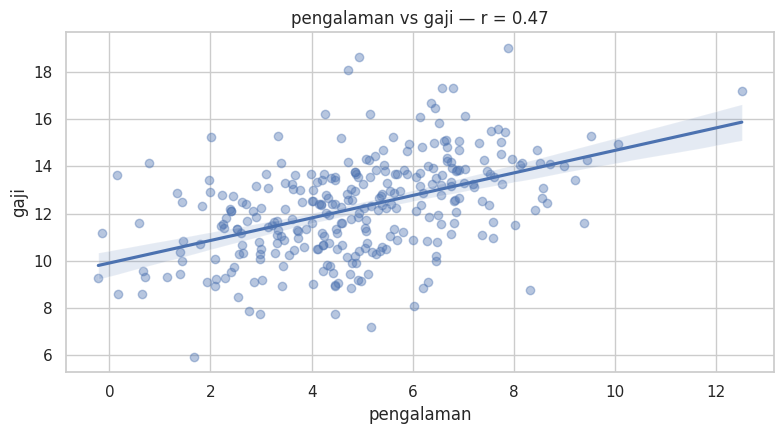

In [8]:
p_h3b = uji_korelasi(df_my, COL_NUM_X, COL_NUM, nama="H3b: korelasi numerik X ~ Y")

**Kesimpulan statistik:** _..._
**Kesimpulan bisnis:** _..._

> Jika hanya memakai satu dari H3a/H3b, hapus sel yang tidak dipakai agar tabel ringkasan rapi.

# 📊 8. Ringkasan Semua Uji

In [9]:
ringkasan()

,Hipotesis,Uji,p-value,Effect size,Keputusan (α=0.05)
0,H1: numerik beda antar 2 grup,Student t,0.9171,d = -0.012,GAGAL TOLAK H0
1,H2: kategorik A ⟂ B,Chi-square,1.0000,V = 0.000,GAGAL TOLAK H0
2,H3a: numerik beda antar ≥3 grup,One-way ANOVA,0.5785,η² = 0.004,GAGAL TOLAK H0
3,H3b: korelasi numerik X ~ Y,Pearson r,9.84e-18,r = 0.468,TOLAK H0


# ✅ 9. Checklist Submit Milestone 2

- [ ] Minimal 1 CI 95% untuk metrik utama
- [ ] 2–3 hipotesis berasal dari insight Milestone 1
- [ ] Tiap hipotesis: H₀, H₁, α, alasan uji, cek asumsi
- [ ] Statistik uji + p-value + effect size
- [ ] Kesimpulan statistik + bahasa bisnis
- [ ] `DATA_PATH` sudah diganti ke dataset Anda (bukan data demo)
- [ ] README diperbarui, commit: `"Milestone 2: hypothesis testing"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 11**